# Reto 2 — Reconocimiento de objetos y orientación con ML clásico

**Problema.** Dada la imagen de un producto en orientación arbitraria, decidir **qué objeto es**, **en qué ángulo
está** (giro sobre el eje vertical, 0–360°), **con qué confianza**, **qué vistas de referencia se le parecen** y
**si es seguro que el robot actúe** (tolerancia de agarre ±10°).

**Enfoque (tres piezas + control de seguridad).**
1. **Identidad**: características clásicas (color HSV, forma HOG, textura LBP) → clasificador estadístico. La
   distancia a la vista de referencia más cercana es la puntuación de "desconocido".
2. **Modelo del plato** (Murase & Nayar, 1995): el objeto solo gira sobre el eje vertical (1 grado de libertad),
   así que sus apariencias forman una **curva cerrada** en un espacio PCA, parametrizada por el ángulo. El ángulo
   de una imagen nueva es el punto más cercano de la curva; el perfil de distancias da la incertidumbre.
3. **Similitud híbrida**: top-k por pose (mismo SKU, ángulo cercano: explica la decisión) + top-k por apariencia
   (independiente de la predicción: es la evidencia).
4. **Control de seguridad determinista**: ACT / ANGLE_UNCERTIFIED / REVIEW / UNKNOWN con umbrales calibrados.

**Rigor.** Ningún hiperparámetro ni umbral ve la prueba: todo se fija en **particiones internas** construidas solo
con vistas de entrenamiento que imitan cada protocolo. El criterio de selección está **pre-registrado** en
`configs/model.yaml`. Cada protocolo se evalúa **una sola vez**. Todo queda registrado en MLflow.

| Sección | Contenido |
|---|---|
| 1 | Configuración, datos y trazabilidad |
| 2 | Análisis exploratorio: propiedades que condicionan el diseño y brecha con planta |
| 3 | Protocolos y validación interna |
| 4 | Selección del modelo de identidad (≥3 clasificadores × representaciones) |
| 5 | Modelo del plato: método y visualización de las curvas |
| 6 | Evaluación final por protocolo |
| 7 | Baseline simple y referencia moderna (DINOv2) |
| 8 | Análisis de errores |
| 9 | Sector ciego: mitigación con 2a captura |
| 10 | Artefacto final versionado y model card |

## 1. Configuración, datos y trazabilidad

In [1]:
import json, logging, os, time, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
logging.getLogger("alembic").setLevel(logging.WARNING)
logging.getLogger("mlflow").setLevel(logging.WARNING)

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from linevision import analysis, tracking
from linevision.config import ROOT, cache_dir, data_dir, load_config
from linevision.data import load_coil100
from linevision.experiment import (evaluate, evaluate_baseline, production_system, run_protocol, two_shot)
from linevision.features import extract, extract_cached
from linevision.identity import IdentityConfig
from linevision.pose import PoseConfig, PoseModel
from linevision.protocols import inner_splits, make_protocol
from linevision.reference import dino_embeddings
from linevision.registry import export, register
from linevision.report import model_card, protocol_table
from linevision.selection import candidates, compare_pose_methods, openset_by_blocks, screen_identity, select
from linevision.system import SystemConfig

pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

MODEL_CFG, PROT_CFG = load_config("model"), load_config("protocols")
TOL = MODEL_CFG["gate"]["tolerance_deg"]
ITERATION = "v2"  # ver "Registro de iteraciones" (sección 6)
tracking.DEFAULT_TAGS["iteracion"] = ITERATION
uri = tracking.setup()
print("MLflow:", uri)

./.venv/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


MLflow: sqlite:///./mlflow.db


In [2]:
t0 = time.time()
ds = load_coil100(data_dir())
print(f"{len(ds)} imágenes, {len(np.unique(ds.obj))} objetos, versión de datos {ds.version} ({time.time() - t0:.1f}s)")
BASE_CFG = SystemConfig.from_model_config(MODEL_CFG)
t0 = time.time()
feats = extract_cached(ds.images, BASE_CFG.features, ds.version, cache_dir())
print(f"características en {time.time() - t0:.1f}s:", {k: v.shape for k, v in feats.items()})
OBJ, ANG = ds.obj, ds.angle

7200 imágenes, 100 objetos, versión de datos 4e39f8783785bc2d (4.7s)


características en 0.3s: {'raw': (7200, 3072), 'hsv': (7200, 256), 'hog': (7200, 1764), 'lbp': (7200, 28)}


## 2. Análisis exploratorio

Objetivo: caracterizar el dataset e identificar qué propiedades condicionan el diseño del modelo y de sus métricas.

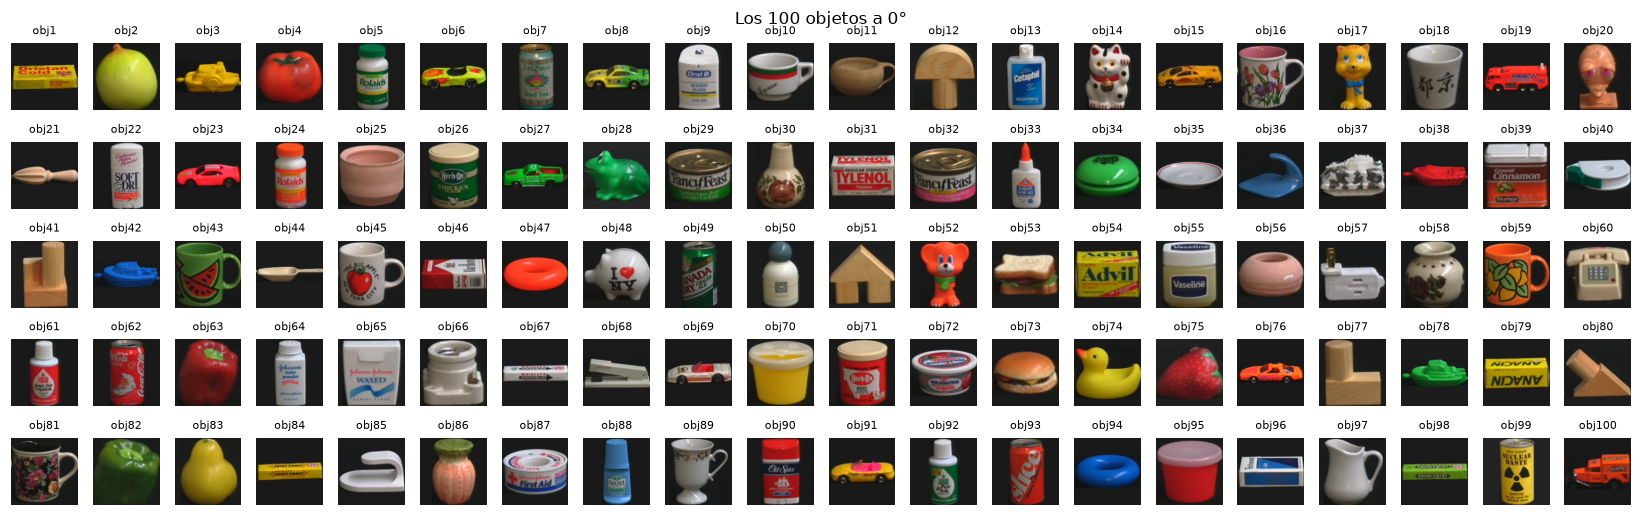

In [3]:
first = ds.images[ANG == 0]
fig = analysis.montage(first, 20, [f"obj{o}" for o in range(1, 101)], size=0.75)
fig.suptitle("Los 100 objetos a 0°", y=1.0); plt.show()

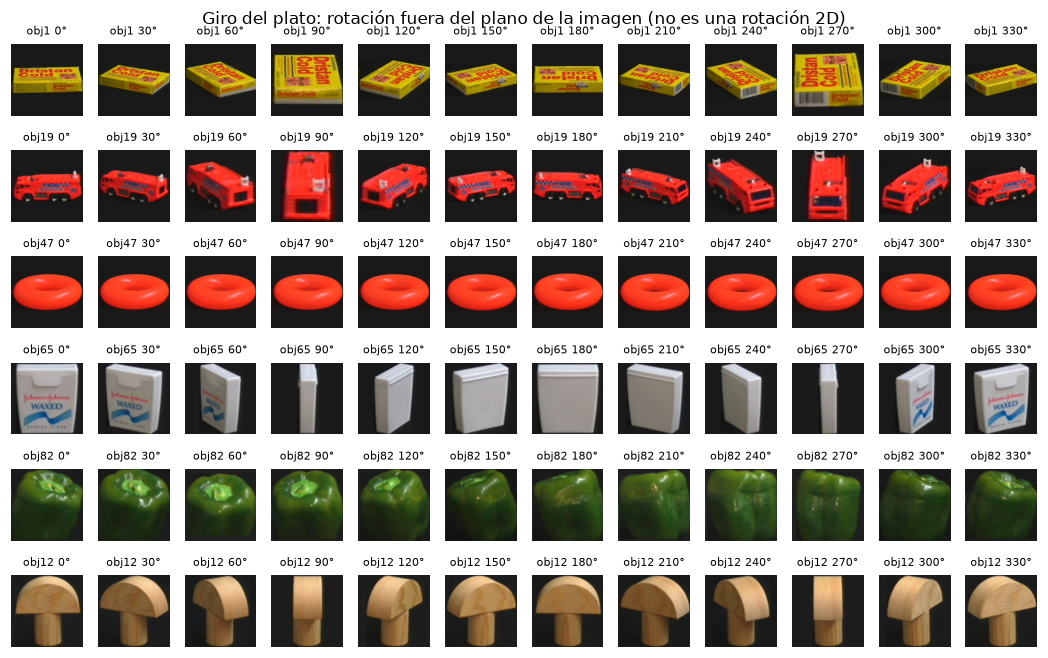

In [4]:
objs = [1, 19, 47, 65, 82, 12]
strip = np.concatenate([ds.images[(OBJ == o) & (ANG % 30 == 0)] for o in objs])
fig = analysis.montage(strip, 12, [f"obj{o} {a}°" for o in objs for a in range(0, 360, 30)], size=0.8)
fig.suptitle("Giro del plato: rotación fuera del plano de la imagen (no es una rotación 2D)", y=1.0); plt.show()

In [5]:
corners = np.concatenate([ds.images[:, :8, :8].reshape(-1, 3), ds.images[:, :8, -8:].reshape(-1, 3)])
mx = ds.images.max(-1)
fg = mx > BASE_CFG.features.fg_threshold
touch = fg[:, 0, :].any(1) | fg[:, -1, :].any(1) | fg[:, :, 0].any(1) | fg[:, :, -1].any(1)
area = fg.mean((1, 2))
area_cv = pd.Series(area).groupby(OBJ).agg(lambda s: s.std() / s.mean())
eda = pd.Series({
    "fondo: media RGB de esquinas": corners.mean(0).round(1).tolist(),
    "fondo: percentil 99 (máx. canal)": float(np.percentile(corners.max(1), 99)),
    "primer plano medio (fracción)": round(float(area.mean()), 3),
    "imágenes donde el objeto toca el borde": f"{touch.mean():.1%}",
    "variación del área con el giro (CV mediano)": round(float(area_cv.median()), 3),
    "imágenes duplicadas exactas": int(len(ds) - len({im.tobytes() for im in ds.images})),
})
eda.to_frame("valor")

,valor
fondo: media RGB de esquinas,"[26.4, 26.4, 25.9]"
fondo: percentil 99 (máx. canal),53.0
primer plano medio (fracción),0.462
imágenes donde el objeto toca el borde,60.1%
variación del área con el giro (CV mediano),0.102
imágenes duplicadas exactas,0


**Propiedades que condicionan el diseño**

| Propiedad observada | Consecuencia en el diseño |
|---|---|
| Rotación sobre el eje vertical (plato), 1 grado de libertad, paso 5° | El ángulo es una pose fuera del plano: rotar la imagen en 2D **no** lo simula ni lo mide (descarta YOLO-OBB/OpenCV). Las apariencias de un objeto forman una curva cerrada → modelo del plato. |
| El 0° de cada objeto es arbitrario (posición inicial del plato) | El ángulo es relativo a la vista de referencia de cada SKU: la pose se estima **condicionada a la clase**. Un SKU nuevo necesita su galería de referencia. |
| Objetos con simetría (rosca obj47, cajas obj65/obj67, setas obj12) | Ángulo indeterminado módulo la simetría: métrica circular **y** consciente de simetría; la incertidumbre debe poder ser multimodal. |
| Vistas a 5° casi idénticas | Nunca K-fold aleatorio (fuga): validación por bloques de ángulo/objeto que imita cada protocolo. |
| Fondo oscuro no negro (~26/255), imágenes recortadas y escaladas por objeto | Umbral de primer plano calibrado (60); la escala aparente cambia con el giro (no es una señal fiable de pose). |
| Pares visualmente cercanos (coches rojos, objetos amarillos, piezas de madera) | Riesgo de confusión entre clases y de aceptar "gemelos" desconocidos: escenario adverso en D. |

**Diferencias con un entorno real de planta y cómo se abordan**

| COIL-100 | Planta | Cómo se aborda |
|---|---|---|
| Un objeto, centrado y recortado | Posición y escala variables, varios objetos | Etapa previa de segmentación/recorte (fondo controlado de la cinta) antes del modelo; fuera del alcance del dataset, declarado en la model card. |
| Iluminación fija de laboratorio | Deriva de iluminación, suciedad en la cámara | El color domina la identidad → monitorizar la novedad y la salud de cámara; recalibrar con imágenes de planta. |
| Solo giro vertical | Objeto volcado/inclinado | Fuera de dominio: lo captura la novedad (UNKNOWN/REVIEW), no se inventa un ángulo. |
| Galería completa de 72 vistas | Alta de SKU con pocas vistas | Protocolo C y certificación de cobertura angular por SKU. |
| Sin oclusión ni desenfoque | Movimiento en la cinta | Control de calidad de imagen antes de inferir (Reto 3). |

## 3. Protocolos y validación interna

Un protocolo **no** es un problema distinto: es un reparto distinto de vistas entre entrenamiento y prueba que
estresa una capacidad. El mismo sistema se entrena por protocolo con su entrenamiento, se calibra con particiones
internas (solo vistas de entrenamiento) y se evalúa una vez en su prueba. B y D se repiten con 3 semillas
(posición del arco ciego y objetos excluidos).

| Protocolo | Entrena / prueba | Estresa | Validación interna (solo entrenamiento) |
|---|---|---|---|
| A — Interpolación | 0°,10°,… / 5°,15°,… | plato interpolando | 2 pliegues: 0°,20°,… ↔ 10°,30°,… (espaciado doble, más exigente) |
| B — Sector ciego | 300° / arco de 60° | saber cuándo no fiarse del plato | 3 pliegues: otro arco de 60° dentro de la región vista |
| C — Escasez | 12 vistas (30°) / 60 restantes | identidad y plato con pocos datos | 2 pliegues: 0°,60°,… ↔ 30°,90°,… |
| D — Desconocido | 90 objetos / 10 objetos nuevos | rechazo | 3 pliegues: 10 objetos de catálogo hacen de desconocidos |

In [6]:
splits = {p: [make_protocol(p, OBJ, ANG, PROT_CFG, r) for r in range(PROT_CFG[p].get("repeats", 1))]
          for p in "ABCD"}
rows = []
for p, sps in splits.items():
    for r, sp in enumerate(sps):
        inner = inner_splits(sp, OBJ, ANG)
        rows.append({"protocolo": p, "repetición": r, "entrenamiento": len(sp.train), "prueba": len(sp.test),
                     "desconocidos": sp.unknown_objects or "—", "pliegues internos": len(inner),
                     "solapamiento interno∩prueba": sum(len(np.intersect1d(np.r_[i.train, i.test], sp.test)) for i in inner)})
pd.DataFrame(rows)

,protocolo,repetición,entrenamiento,prueba,desconocidos,pliegues internos,solapamiento interno∩prueba
0,A,0,3600,3600,—,2,0
1,B,0,6000,1200,—,3,0
2,B,1,6000,1200,—,3,0
3,B,2,6000,1200,—,3,0
4,C,0,1200,6000,—,2,0
5,D,0,6480,720,"(3, 8, 17, 35, 36, 37, 45, 61, 64, 78)",3,0
6,D,1,6480,720,"(1, 8, 14, 28, 37, 45, 47, 49, 58, 91)",3,0
7,D,2,6480,720,"(23, 33, 34, 36, 52, 56, 71, 85, 96, 97)",3,0


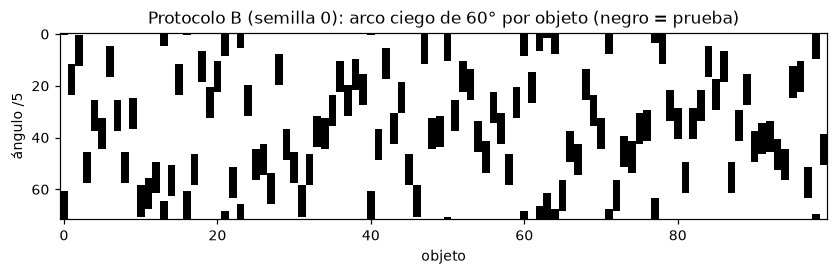

In [7]:
sp = splits["B"][0]
fig, ax = plt.subplots(figsize=(9, 2.2))
m = np.zeros((100, 72)); m[OBJ[sp.test] - 1, ANG[sp.test] // 5] = 1
ax.imshow(m.T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xlabel("objeto"); ax.set_ylabel("ángulo /5"); ax.set_title("Protocolo B (semilla 0): arco ciego de 60° por objeto (negro = prueba)")
plt.show()

## 4. Selección del modelo de identidad

Matriz **representaciones × clasificadores** (≥3 algoritmos: kNN, regresión logística, SVM-RBF, Random Forest)
evaluada en las particiones internas de A, B y C. `raw` + `knn1` es el baseline PCA + 1-NN.

**Criterio pre-registrado** (`configs/model.yaml`, fijado antes de ver resultados):
1. restricción de seguridad: en la validación interna de D, desconocidos aceptados ≤ 5 % cuando se acepta el
   95 % de los conocidos (depende solo de la representación);
2. máxima exactitud del **peor caso** entre A, B y C;
3. empates (< 0,5 pp) → menor latencia.

Se reporta también el AURC (área bajo la curva riesgo-cobertura de la confianza; menor es mejor) para juzgar si
la confianza es una base útil para decidir.

In [8]:
inner = {p: inner_splits(splits[p][0], OBJ, ANG) for p in "ABC"}
inner_d = inner_splits(splits["D"][0], OBJ, ANG)
cands = candidates(MODEL_CFG)
print(f"{len(cands)} candidatos × {sum(len(v) for v in inner.values())} ajustes internos")

openset = {}
for blocks in {c.blocks for c in cands}:
    openset[blocks] = openset_by_blocks(blocks, feats, OBJ, ANG, inner_d)

rows = []
t0 = time.time()
with tracking.run("seleccion-identidad", ds.version, {"etapa": "seleccion"}) as parent:
    for c in cands:
        row = screen_identity(c, feats, OBJ, ANG, inner)
        row["worst_acc"] = min(row[f"acc_{p}"] for p in "ABC")
        row["unknown_accepted"] = openset[c.blocks]["unknown_accepted"]
        row["openset_auroc"] = openset[c.blocks]["auroc"]
        rows.append(row)
        with mlflow.start_run(run_name=c.name, nested=True):
            mlflow.set_tags(tracking.DEFAULT_TAGS)
            mlflow.log_params({"blocks": row["blocks"], "classifier": c.classifier, **c.params})
            tracking.log_metrics({k: v for k, v in row.items() if isinstance(v, float)})
print(f"selección en {time.time() - t0:.0f}s")
table = pd.DataFrame(rows)
sel_cfg = MODEL_CFG["identity"]["selection"]
winner = select(table, sel_cfg["max_unknown_accepted"], sel_cfg["tie_tolerance_pp"])
cols = ["candidate", "acc_A", "acc_B", "acc_C", "worst_acc", "aurc_A", "aurc_C", "unknown_accepted", "openset_auroc", "predict_ms", "fit_s"]
table.sort_values("worst_acc", ascending=False)[cols].reset_index(drop=True)

35 candidatos × 7 ajustes internos


selección en 812s


,candidate,acc_A,acc_B,acc_C,worst_acc,aurc_A,aurc_C,unknown_accepted,openset_auroc,predict_ms,fit_s
0,hsv|rf(n_estimators=500),0.9975,0.9867,0.9850,0.9850,4.1926e-05,0.0007,0.0102,0.9976,0.2718,18.8964
1,hsv+hog+lbp|logreg(C=10.0),0.9997,0.9842,0.9700,0.9700,1.5434e-07,0.0012,0.0000,0.9999,0.0073,0.1589
2,hsv+hog+lbp|logreg(C=1.0),0.9997,0.9856,0.9683,0.9683,1.5434e-07,0.0013,0.0000,0.9999,0.0072,0.1619
3,hsv+hog+lbp|svm_rbf(C=1.0),1.0000,0.9883,0.9683,0.9683,0.0000e+00,0.0022,0.0000,0.9999,0.5942,0.8976
4,hsv+hog+lbp|svm_rbf(C=10.0),1.0000,0.9881,0.9675,0.9675,0.0000e+00,0.0018,0.0000,0.9999,0.8067,0.8408
5,hsv+hog+lbp|svm_rbf(C=100.0),1.0000,0.9881,0.9675,0.9675,0.0000e+00,0.0018,0.0000,0.9999,0.7369,1.1595
6,hsv|logreg(C=1.0),0.9953,0.9806,0.9650,0.9650,4.6377e-05,0.0035,0.0102,0.9976,0.0051,0.2361
7,hsv|logreg(C=10.0),0.9953,0.9794,0.9650,0.9650,5.4202e-05,0.0053,0.0102,0.9976,0.0052,0.1865
8,hsv|svm_rbf(C=100.0),0.9975,0.9683,0.9608,0.9608,4.4243e-04,0.0123,0.0102,0.9976,1.5158,2.1392
9,hsv|svm_rbf(C=10.0),0.9981,0.9686,0.9608,0.9608,5.9877e-05,0.0123,0.0102,0.9976,1.5643,2.1396


GANADOR: hsv|rf(n_estimators=500)


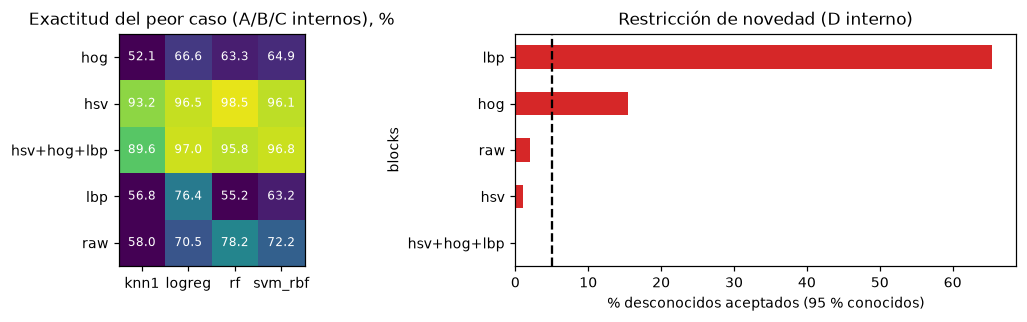

In [9]:
print("GANADOR:", winner["candidate"])
pivot = table.pivot_table(index="blocks", columns="classifier", values="worst_acc", aggfunc="max")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
im = axes[0].imshow(pivot.values * 100, cmap="viridis", vmin=60, vmax=100)
axes[0].set_xticks(range(len(pivot.columns)), pivot.columns); axes[0].set_yticks(range(len(pivot.index)), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        axes[0].text(j, i, f"{pivot.values[i, j] * 100:.1f}", ha="center", va="center", color="w", fontsize=8)
axes[0].set_title("Exactitud del peor caso (A/B/C internos), %")
os_df = pd.DataFrame([{"blocks": "+".join(b), **v} for b, v in openset.items()]).set_index("blocks")
(os_df["unknown_accepted"] * 100).sort_values().plot.barh(ax=axes[1], color="tab:red")
axes[1].axvline(sel_cfg["max_unknown_accepted"] * 100, ls="--", c="k"); axes[1].set_xlabel("% desconocidos aceptados (95 % conocidos)")
axes[1].set_title("Restricción de novedad (D interno)")
plt.tight_layout(); plt.show()

**Lectura.** La elección de la **representación** pesa mucho más que la del clasificador: entre clasificadores con
la misma representación las diferencias son de pocos puntos, entre representaciones de decenas. Los píxeles con
PCA (baseline) no cumplen la restricción de seguridad: aceptan una fracción alta de objetos desconocidos.

## 5. Modelo del plato

Comparación en validación interna (con la clase verdadera, para aislar el plato) entre el ángulo de la vista más
cercana (1-NN) y la curva cerrada con spline periódico.

In [10]:
pose_cfg = BASE_CFG.pose
pose_table = compare_pose_methods(feats, OBJ, ANG, inner, pose_cfg, TOL)
pose_table

,protocolo,método,n,within_tol,mae,median,p90,gt90
0,A,1-NN (vista más cercana),3600,0.9422,17.2000,10.00,10.00,0.0414
1,A,curva cerrada (spline periódico),3600,0.9636,2.9843,1.00,4.50,0.0044
2,B,1-NN (vista más cercana),3600,0.2892,52.3847,20.00,175.00,0.2258
3,B,curva cerrada (spline periódico),3600,0.6028,30.6522,7.00,171.00,0.1317
4,C,1-NN (vista más cercana),1200,0.0000,51.3500,30.00,150.00,0.1600
5,C,curva cerrada (spline periódico),1200,0.5158,30.0221,9.75,148.25,0.1175


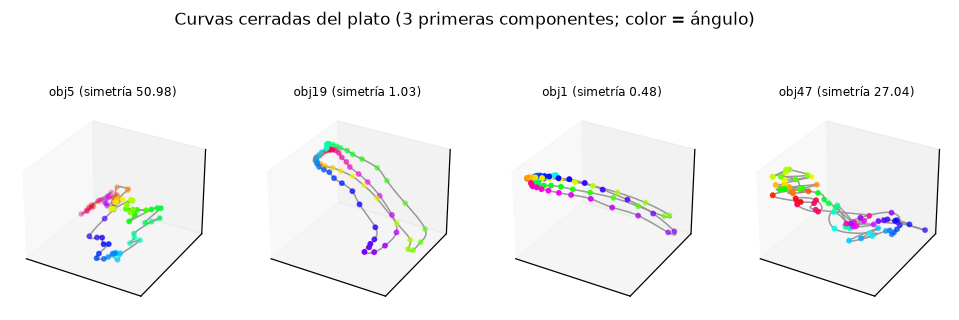

In [11]:
viz = PoseModel(PoseConfig(pca_dim=3)).fit(feats["raw"], OBJ, ANG)
fig = plt.figure(figsize=(11, 3.4))
for k, o in enumerate([5, 19, 1, 47]):
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    c = viz.curves[o]; z = viz.gallery_z[o]
    ax.plot(c[:, 0], c[:, 1], c[:, 2], lw=1, c="0.6")
    sc = ax.scatter(z[:, 0], z[:, 1], z[:, 2], c=viz.gallery_angles[o], cmap="hsv", s=8)
    ax.set_title(f"obj{o} (simetría {viz.symmetry_score[o]:.2f})", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle("Curvas cerradas del plato (3 primeras componentes; color = ángulo)", y=1.02)
plt.show()

Cada objeto traza un lazo cerrado: es la representación "pseudo-3D" del giro. Un objeto con simetría de orden 2
recorre el lazo dos veces casi por el mismo sitio (vistas opuestas cercanas); la rosca (obj47) colapsa en una
región pequeña: su ángulo no es observable. La puntuación de simetría (distancia entre vistas opuestas relativa
a vistas a 10°) cuantifica esto sin mirar la prueba.

## 6. Evaluación final por protocolo

Para cada protocolo y repetición: calibración en validación interna → entrenamiento con todo el entrenamiento →
**una** evaluación en prueba. Identidad = ganador de la sección 4.

**Calibración.** Identidad y novedad se calibran con las particiones internas que imitan el protocolo. La
incertidumbre del ángulo (temperatura) y su umbral de riesgo se calibran en el **régimen con cobertura**
(alternancia de vistas consecutivas del entrenamiento): el sector ciego no se modela con incertidumbre sino con
la regla determinista de certificación de cobertura del SKU.

**Criterio de aceptación (tolerancia del robot ±10°).** El robot solo actúa si (a) la clase es confiable y la
evidencia por apariencia coincide, (b) el SKU tiene cobertura angular certificada, (c) el conjunto creíble del 90 %
del ángulo cabe en ±10° y (d) la ambigüedad está bajo un umbral calibrado para que **≥ 99,5 % de los casos ACT
queden dentro de ±10°** en validación interna (objetivo pre-declarado en `configs/model.yaml`).

### Registro de iteraciones (transparencia)

| Iteración | Cambio | Motivo | Cómo se calibra |
|---|---|---|---|
| v1 | Control de seguridad con "conjunto creíble ≤ 20°" (traducción geométrica de la tolerancia). Temperatura calibrada en las particiones internas de cada protocolo (en B, dentro de sectores ciegos). | — | Validación interna |
| v2 | (1) Se añade el umbral de **ambigüedad** con objetivo explícito de riesgo angular (≤ 0,5 % de ACT fuera de ±10°). (2) La temperatura y el umbral del ángulo se calibran en el **régimen con cobertura**. | La primera evaluación mostró 1,0 % de acciones inseguras en A y una 2a captura demasiado conservadora en B. El diagnóstico **en validación interna** confirmó que el problema ya era visible ahí (1,05 % de errores > 10° entre los que pasaban el control) y que la ambigüedad lo separa (AUROC 0,95–0,98). | Exclusivamente validación interna; la prueba no interviene en ningún umbral. |

Los resultados v1 se conservan en MLflow (etiqueta `iteracion=v1`) y en `reports/results_v1.json`. El
clasificador seleccionado no cambia entre iteraciones (la selección no depende del control de seguridad).

In [12]:
best_ident = next(c for c in cands if c.name == winner["candidate"])
SYS_CFG = SystemConfig.from_model_config(MODEL_CFG, identity=best_ident)
results, diags, details, systems = {p: [] for p in "ABCD"}, [], {}, {}
t0 = time.time()
for p, sps in splits.items():
    for r, sp in enumerate(sps):
        system, diag = run_protocol(SYS_CFG, feats, OBJ, ANG, sp, MODEL_CFG["gate"], version=f"{p}{r}")
        res, det = evaluate(system, feats, OBJ, ANG, sp, TOL)
        results[p].append(res); details[(p, r)] = det; systems[(p, r)] = system
        diags.append({"protocolo": p, "rep": r, **tracking.flatten(diag)})
        with tracking.run(f"final-{p}-rep{r}", ds.version, {"etapa": "evaluacion", "protocolo": p},
                          {"identity": best_ident.name, "seed": sp.meta.get("seed", PROT_CFG["seed"])}):
            tracking.log_metrics(res, "test.")
            tracking.log_metrics(diag, "inner.")
            tracking.log_json({"test": res, "inner": diag}, f"metrics_{p}{r}.json")
print(f"evaluación en {time.time() - t0:.0f}s")
pd.DataFrame(diags).set_index(["protocolo", "rep"])[[
    "inner_class_acc", "inner_pose.within_tol", "temperature_scale", "credible_coverage", "ambiguity_max",
    "inner_angle_gate.pass_rate", "inner_angle_gate.error_rate_on_pass", "class_conf_min", "novelty_max",
    "inner_openset.auroc", "inner_openset.unknown_accepted"]]

evaluación en 340s


inner_class_acc  inner_pose.within_tol  temperature_scale  credible_coverage  ambiguity_max  inner_angle_gate.pass_rate  inner_angle_gate.error_rate_on_pass  class_conf_min  \
protocolo rep                                                                                                                                                                                 
A         0             0.9975                 0.9636             0.0398             0.9064         0.8906                      0.7069                               0.0047           0.198   
B         0             0.9867                 0.9737             0.0398             0.9065         0.7784                      0.8765                               0.0049           0.392   
          1             0.9803                 0.9753             0.0501             0.9122         0.7480                      0.8640                               0.0048           0.482   
          2             0.9728                 0.9742             0.0501             0.9142         0.7845                      0.8625                               0.0048           0.544   
C         0             0.9850                 0.5158             0.2509             0.9033         0.0000                      0.0000                                  NaN           0.226   
D         0             0.9993                 0.9722             0.0398             0.9088         0.7752                      0.8668                               0.0050           0.298   
          1             0.9991                 0.9755             0.0398             0.9108         0.7862                      0.8708                               0.0050           0.306   
          2             0.9997                 0.9738             0.0398             0.9111         0.7695                      0.8748                               0.0049           0.282   

               novelty_max  inner_openset.auroc  inner_openset.unknown_accepted  
protocolo rep                                                                    
A         0         0.2483                  NaN                             NaN  
B         0         0.3620                  NaN                             NaN  
          1         0.3848                  NaN                             NaN  
          2         0.3634                  NaN                             NaN  
C         0         0.4101                  NaN                             NaN  
D         0         0.1828               0.9976                          0.0102  
          1         0.1840               0.9925                          0.0250  
          2         0.1869               0.9723                          0.0449

In [13]:
final_table = protocol_table(results)
final_table

,corridas,clase,ángulo ±tol (clase dada),ángulo ±tol (con simetría),mediana error (°),ACT,ángulo no certificado,revisión,desconocido,acciones inseguras,ángulo ±tol cuando actúa,desconocidos rechazados,latencia (ms/img)
protocolo,,,,,,,,,,,,,
A,1,99.9,97.0,97.1,0.5,87.6,12.1,0.2,0.1,0.7,99.2,—,0.2
B,3,99.0 ± 0.4,55.3 ± 1.6,60.9 ± 1.6,8.2 ± 0.5,0.0 ± 0.0,93.1 ± 1.8,6.1 ± 1.7,0.8 ± 0.4,0.0 ± 0.0,—,—,0.2 ± 0.1
C,1,99.6,95.0,95.5,1.5,0.0,99.3,0.7,0.0,0.0,—,—,0.1
D,3,—,—,—,—,0.0 ± 0.0,0.1 ± 0.2,0.0 ± 0.1,99.8 ± 0.3,0.0 ± 0.0,—,99.8 ± 0.3,0.1 ± 0.0


## 7. Baseline simple y referencia moderna

- **Baseline simple**: PCA sobre píxeles + 1-NN (clase) y ángulo de la vista más cercana; sin control de seguridad.
- **Referencia moderna** (obligatoria, solo comparación): embeddings auto-supervisados **DINOv2-small** como bloque
  de características, con el **mismo** pipeline (regresión logística, curva cerrada del plato sobre los
  embeddings, mismo control de seguridad y misma calibración). Aísla el efecto de la representación profunda.

In [14]:
emb, dino_info = dino_embeddings(ds.images, ds.version, cache_dir())
print(dino_info)
feats_ref = {**feats, "dino": emb}
ref_cfg = MODEL_CFG["reference"]
REF_CFG = SystemConfig.from_model_config(
    MODEL_CFG, identity=IdentityConfig(("dino",), ref_cfg["classifier"], ref_cfg["params"], MODEL_CFG["identity"]["pca_dim"]))
REF_CFG.pose.block = "dino"

base_results, ref_results = {p: [] for p in "ABCD"}, {p: [] for p in "ABCD"}
for p, sps in splits.items():
    for r, sp in enumerate(sps):
        base_results[p].append(evaluate_baseline(feats, OBJ, ANG, sp, TOL))
        system, _ = run_protocol(REF_CFG, feats_ref, OBJ, ANG, sp, MODEL_CFG["gate"], version=f"ref-{p}{r}")
        ref_results[p].append(evaluate(system, feats_ref, OBJ, ANG, sp, TOL)[0])
with tracking.run("comparacion-baseline-referencia", ds.version, {"etapa": "comparacion"}):
    tracking.log_json({"baseline": base_results, "referencia": ref_results}, "comparacion.json")

{'model': 'facebook/dinov2-small', 'ms_per_image': 8.640457656250266, 'device': 'mps'}


In [15]:
# coste de extracción de características por imagen (CPU) para el clásico
t0 = time.perf_counter(); _ = extract(ds.images[:300], BASE_CFG.features); classic_feat_ms = (time.perf_counter() - t0) / 300 * 1000
keys = ["clase", "ángulo ±tol (clase dada)", "acciones inseguras", "desconocidos rechazados", "latencia (ms/img)"]
cmp = pd.concat({"baseline PCA+1-NN": protocol_table(base_results)[keys],
                 f"clásico ({best_ident.name})": final_table[keys],
                 "referencia DINOv2": protocol_table(ref_results)[keys]}, names=["modelo"]).swaplevel().sort_index()
print(f"extracción de características: clásico {classic_feat_ms:.1f} ms/img (CPU) | DINOv2 {dino_info['ms_per_image']:.1f} ms/img ({dino_info['device']})")
cmp

extracción de características: clásico 2.1 ms/img (CPU) | DINOv2 8.6 ms/img (mps)


clase ángulo ±tol (clase dada) acciones inseguras desconocidos rechazados latencia (ms/img)
protocolo modelo                                                                                                                              
A         baseline PCA+1-NN                         99.8                     96.1                4.1                       —               0.0
          clásico (hsv|rf(n_estimators=500))        99.9                     97.0                0.7                       —               0.2
          referencia DINOv2                        100.0                     95.3                0.4                       —               0.0
B         baseline PCA+1-NN                   84.2 ± 0.8               28.2 ± 0.1         72.7 ± 0.1                       —         0.0 ± 0.0
          clásico (hsv|rf(n_estimators=500))  99.0 ± 0.4               55.3 ± 1.6          0.0 ± 0.0                       —         0.2 ± 0.1
          referencia DINOv2                   99.8 ± 0.3               21.8 ± 0.3          0.0 ± 0.0                       —         0.0 ± 0.0
C         baseline PCA+1-NN                         94.2                     74.1               28.3                       —               0.0
          clásico (hsv|rf(n_estimators=500))        99.6                     95.0                0.0                       —               0.1
          referencia DINOv2                        100.0                     87.7                0.0                       —               0.0
D         baseline PCA+1-NN                            —                        —        100.0 ± 0.0               0.0 ± 0.0         0.0 ± 0.0
          clásico (hsv|rf(n_estimators=500))           —                        —          0.0 ± 0.0              99.8 ± 0.3         0.1 ± 0.0
          referencia DINOv2                            —                        —          0.0 ± 0.1              93.1 ± 2.7         0.0 ± 0.0

## 8. Análisis de errores

Protocolo C — pares más confundidos (verdadero → predicho):


,verdadero,predicho,n
0,51,12,7
1,11,12,4
2,51,80,3
3,12,77,2
4,41,80,2
5,80,41,2
6,9,97,1
7,51,41,1


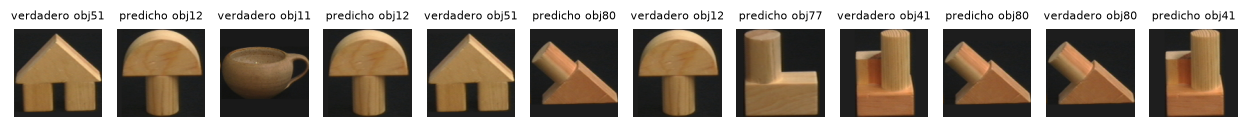

In [16]:
det_c = details[("C", 0)]
pairs = analysis.confusion_pairs(det_c, 8)
print("Protocolo C — pares más confundidos (verdadero → predicho):")
display(pairs)
imgs, titles = [], []
for _, row in pairs.head(6).iterrows():
    imgs += [ds.images[(OBJ == row.verdadero) & (ANG == 0)][0], ds.images[(OBJ == row.predicho) & (ANG == 0)][0]]
    titles += [f"verdadero obj{row.verdadero}", f"predicho obj{row.predicho}"]
analysis.montage(np.array(imgs), 12, titles, size=0.95); plt.show()

In [17]:
sys_a = systems[("A", 0)]
po = analysis.per_object_pose(details[("A", 0)], TOL, sys_a.pose.symmetry_score)
print("Protocolo A — objetos con mayor error de ángulo (clase dada):")
display(po.head(8))
sym_objs = [o for o, s in sys_a.pose.symmetry_score.items() if s < 1]
print(f"objetos con simetría de orden 2 estimada (puntuación < 1): {sorted(int(o) for o in sym_objs)}")

Protocolo A — objetos con mayor error de ángulo (clase dada):


,mae,within_tol,flips_gt150,symmetry_score
obj,,,,
95,13.7500,0.5833,0.0,6.5834
50,12.7639,0.6944,0.0,5.8299
47,7.1250,0.6667,0.0,16.3993
25,6.5972,0.8333,0.0,5.0001
94,6.5833,0.8056,0.0,16.8309
18,6.4028,0.6944,0.0,7.7038
34,6.0278,0.8333,0.0,15.9691
83,5.9444,0.9167,0.0,25.7218


objetos con simetría de orden 2 estimada (puntuación < 1): [1, 12, 31, 33, 65, 66, 67, 79, 84, 98]


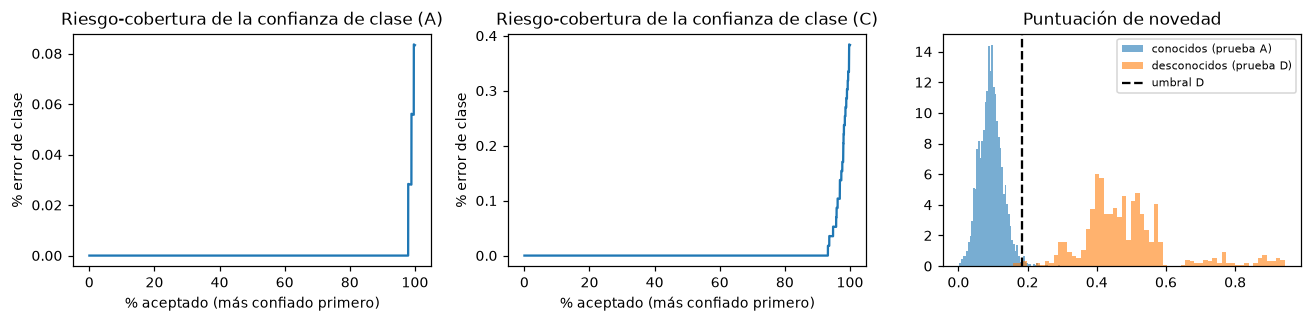

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, p in zip(axes[:2], "AC"):
    d = details[(p, 0)]
    cov, risk = analysis.risk_coverage(d["class_confidence"], d["label"] == d["obj"])
    ax.plot(cov * 100, risk * 100); ax.set_title(f"Riesgo-cobertura de la confianza de clase ({p})")
    ax.set_xlabel("% aceptado (más confiado primero)"); ax.set_ylabel("% error de clase")
d = details[("D", 0)]
known_nov = np.concatenate([details[("A", 0)]["novelty"]])
axes[2].hist(known_nov, bins=60, alpha=.6, density=True, label="conocidos (prueba A)")
axes[2].hist(d["novelty"], bins=60, alpha=.6, density=True, label="desconocidos (prueba D)")
axes[2].axvline(systems[("D", 0)].cfg.policy.novelty_max, c="k", ls="--", label="umbral D")
axes[2].set_title("Puntuación de novedad"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [19]:
from linevision.metrics import circular_error
d = details[("B", 0)]
err = circular_error(d["pose_true_class_angle"], d["true_angle"])
print("Protocolo B — decisiones del control de seguridad en el arco ciego:")
display(pd.Series(d["decision"]).value_counts(normalize=True).rename("fracción").to_frame())
print(f"ángulo (una imagen, clase dada) dentro de ±{TOL}°: {np.mean(err <= TOL):.1%} | errores > 90°: {np.mean(err > 90):.1%}")

Protocolo B — decisiones del control de seguridad en el arco ciego:


,fracción
ANGLE_UNCERTIFIED,0.9417
REVIEW,0.0458
UNKNOWN,0.0125


ángulo (una imagen, clase dada) dentro de ±10°: 53.8% | errores > 90°: 17.7%


## 9. Sector ciego: mitigación con 2a captura

Con una sola imagen el ángulo en un sector nunca visto no es certificable (sección 6–8). Mitigación operativa: girar
el objeto un ángulo conocido (o una 2a cámara desplazada) y estimar con esa 2a imagen. La 2a vista se excluye de la
curva antes de estimar (leave-one-out) para que sea una imagen nueva.

In [20]:
delta = MODEL_CFG["two_shot"]["delta_deg"]
ts = [two_shot(systems[("B", r)], feats, OBJ, ANG, sp, delta, TOL) for r, sp in enumerate(splits["B"])]
two_shot_summary = pd.DataFrame(ts).mean().to_dict()
pd.DataFrame(ts)

,delta_deg,within_tol_all,act_rate,within_tol_on_act,unsafe_rate,mae_on_act
0,180,0.9675,0.9425,0.9894,0.0100,1.4677
1,180,0.9767,0.9333,0.9946,0.0050,1.4121
2,180,0.9767,0.9400,0.9929,0.0067,1.5355


## 10. Artefacto final versionado y model card

Sistema de producción: identidad ganadora + plato + control de seguridad, entrenado con los 100 objetos y las 72
vistas, calibrado con particiones internas tipo D. Se exporta con manifiesto (sha256, versión de datos, huella
de configuración) y se registra en el Model Registry de MLflow.

In [21]:
version = f"{ds.version[:8]}-{best_ident.classifier}"
prod, prod_diag = production_system(SYS_CFG, feats, OBJ, ANG, MODEL_CFG["gate"], version)
t0 = time.perf_counter(); out = prod.predict_images(ds.images[:200]); e2e_ms = (time.perf_counter() - t0) / 200 * 1000
print(f"latencia de punta a punta (imagen → decisión, CPU): {e2e_ms:.1f} ms/img")
print(json.dumps(out[0], indent=1, ensure_ascii=False)[:900])

latencia de punta a punta (imagen → decisión, CPU): 0.9 ms/img
{
 "decision": "ACT",
 "reasons": [],
 "object_id": 1,
 "class_confidence": 0.974,
 "novelty": 0.0,
 "angle_deg": 0.0,
 "angle_credible_width_deg": 2.5,
 "topk_pose": [
  {
   "object_id": 1,
   "angle_deg": 0.0,
   "delta_deg": 0.0
  },
  {
   "object_id": 1,
   "angle_deg": 355.0,
   "delta_deg": 5.0
  },
  {
   "object_id": 1,
   "angle_deg": 5.0,
   "delta_deg": 5.0
  },
  {
   "object_id": 1,
   "angle_deg": 10.0,
   "delta_deg": 10.0
  },
  {
   "object_id": 1,
   "angle_deg": 350.0,
   "delta_deg": 10.0
  }
 ],
 "topk_appearance": [
  {
   "object_id": 1,
   "angle_deg": 0.0,
   "distance": 0.0
  },
  {
   "object_id": 1,
   "angle_deg": 355.0,
   "distance": 0.07595089077949524
  },
  {
   "object_id": 1,
   "angle_deg": 5.0,
   "distance": 0.07984033226966858
  },
  {
   "object_id": 1,
   "angle_deg": 10.0,
   "distance": 0.10491061210632324
  },
  {
   "object_id": 1,
   "angl


In [22]:
art_dir = ROOT / "artifacts"
manifest = export(prod, art_dir, ds.version, {"inner": prod_diag, "e2e_latency_ms": e2e_ms})
with tracking.run(f"produccion-{version}", ds.version, {"etapa": "produccion"}, {"identity": best_ident.name}):
    tracking.log_metrics(prod_diag, "inner."); tracking.log_json(manifest, "manifest.json")
    model_uri = register(art_dir / manifest["artifact"], manifest)
print("artefacto:", manifest["artifact"], f"({manifest['artifact_mb']} MB)", "sha256:", manifest["artifact_sha256"][:16])
print("registrado en MLflow:", model_uri)

2026/10/09 23:13:59 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


2026/10/09 23:14:00 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


artefacto: linevision-4e39f878-rf.joblib (34.6 MB) sha256: 6cf13c982c20411c
registrado en MLflow: models:/m-da13051dd4f7466194ec7f75f5fa988b


Registered model 'linevision' already exists. Creating a new version of this model...
Created version '3' of model 'linevision'.


In [23]:
a_error_on_act = 100 * (1 - results["A"][0]["pose_on_act"]["within_tol"])
card = model_card(version, ds.version, best_ident.name, final_table, cmp, two_shot_summary, TOL,
                  {"max_gallery_gap": SYS_CFG.policy.max_gallery_gap, "a_error_on_act": a_error_on_act})
(ROOT / "reports").mkdir(exist_ok=True)
(ROOT / "reports" / "model_card.md").write_text(card)
json.dump({"final": results, "baseline": base_results, "reference": ref_results, "two_shot": ts,
           "selection_winner": winner["candidate"], "inner": diags},
          open(ROOT / "reports" / "results.json", "w"), indent=1, default=float, ensure_ascii=False)
print("model card → reports/model_card.md | resultados → reports/results.json")

model card → reports/model_card.md | resultados → reports/results.json


## Conclusiones

**Modelo elegido por el criterio pre-registrado.** Identidad = histograma de color HSV + Random Forest (500
árboles): peor caso interno 98,5 % (protocolo C), 1,0 % de desconocidos aceptados (límite 5 %) y el menor AURC de
la matriz (su confianza ordena bien los errores). La combinación HSV+HOG+LBP quedó segunda (97,0 %) con 0 % de
desconocidos aceptados: es la alternativa documentada si en planta la iluminación degrada el color. La decisión
relevante fue la **representación**, no el clasificador.

**Resultados en prueba (una evaluación por protocolo).**
- **A — interpolación**: clase 99,9 %, ángulo ±10° 97,0 % (mediana 0,5°). El robot actúa en el 87,6 % de los
  casos y el 99,2 % de esas acciones queda dentro de ±10° (0,7 % de acciones inseguras frente al 4,1 % del
  baseline). El objetivo de 99,5 % se cumplió en validación interna pero no del todo en prueba: la validación
  interna duplica el espaciado entre vistas.
- **B — sector ciego**: la identidad se mantiene (99,0 %); con una sola imagen el ángulo en el arco nunca visto
  acierta el 55 % (baseline 28 %), así que por política el robot **no actúa** sobre SKUs sin cobertura
  (0 % de acciones inseguras). Con una **2a captura** girando 180°: 97,4 % dentro de ±10°, el robot actúa en el
  93,9 % con 0,7 % de acciones inseguras.
- **C — escasez**: clase 99,6 % y ángulo ±10° 95,0 %, pero con 12 vistas la validación interna (huecos de 60°) no
  puede demostrar el criterio de aceptación y el sistema **no se auto-certifica** (0 % de acciones). Es coherente
  con la política de alta de SKU: galería más densa antes del agarre automático.
- **D — desconocido**: 99,8 % de objetos nuevos rechazados y 0 % de acciones inseguras (baseline: 100 %).

**Referencia moderna (DINOv2).** Mejora la identidad en 0,4–0,8 puntos en B y C, pero empeora el ángulo (B 21,8 %
frente a 55,3 %; C 87,7 % frente a 95,0 %) y el rechazo de desconocidos (93,1 % frente a 99,8 %), y exige GPU y un
modelo de ~22 M de parámetros. **La brecha no justifica su costo, latencia ni complejidad**: el sistema clásico es
mejor en las métricas que determinan la seguridad del agarre.

**Mejoras priorizadas.**
1. Elegir el umbral angular con una cota superior de confianza del error (no con la tasa puntual) para cerrar la
   brecha interna→prueba en A.
2. Política de simetría por SKU y pinza: aceptar el ángulo módulo 180° cuando objeto y pinza son simétricos
   recupera cobertura en cajas y objetos simétricos.
3. Alta de SKU con requisito de densidad de vistas y validación automática (caso de uso del Reto 3).
4. Datos de planta: recalibrar fondo e iluminación y monitorizar la deriva de la puntuación de novedad.